# Using CNN for FER2013 Classification
## Imports:

The following import cell mainly exists as a response to resource-management issues encountered during large-scale CNN 'experimentation'. Early versions of the pipeline produced extensive TensorFlow warning/OOM messages, making it difficult to identify meaningful training output. Suppressing TensorFlow logging significantly improved readability during long experimental runs, though model initialisation remains messy.

RAM and GPU VRAM management became increasingly important as the project expanded to include multiple CNN architectures, repeated training runs, and dynamic batch-size recovery. Without memory growth enabled, TensorFlow attempted to reserve most or all available GPU memory immediately, increasing the likelihood of out-of-memory failures and reducing flexibility when running multiple training sessions.

Mixed-precision training was introduced to further reduce memory usage. By allowing many tensors to be stored in 16-bit precision rather than 32-bit precision, GPU memory requirements were lowered and training throughput improved. This became particularly valuable when experimenting with larger architectures such as ResNet50 and InceptionV3, where memory consumption was substantially higher than that of the baseline CNN models.

The threading configuration was retained to allow TensorFlow to determine appropriate parallelism levels automatically. Combined with dataset optimisation settings, this helped maximise utilisation of available hardware without requiring manual tuning for different execution environments.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import tensorflow as tf
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import gc

from src.config import EMOTION_LABELS, EMOTION_LOOKUP
from src.training import evaluate_model
from src.model_config import CNN_MODELS

tf.get_logger().setLevel("ERROR")

options = tf.data.Options()

options.experimental_optimization.map_parallelization = True
options.experimental_optimization.parallel_batch = True

tf.config.threading.set_inter_op_parallelism_threads(0)
tf.config.threading.set_intra_op_parallelism_threads(0)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

tf.keras.mixed_precision.set_global_policy('mixed_float16')

I0000 00:00:1784980847.286469  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980847.390337  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980847.390396  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980847.391142  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.


Several additional warning-suppression mechanisms were investigated during development in an attempt to eliminate messages such as `W0000 00:00:1784980861.142124  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced` and `'+ptx85' is not a recognized feature for this target`. 

However, these warnings originate from low-level CUDA/XLA components rather than the standard TensorFlow logging system, and as a result, they cannot be reliably suppressed through normal TensorFlow logging controls - and were ultimately accepted as harmless startup messages. The final configuration hence focuses on suppressing controllable TensorFlow output, improving GPU memory behaviour, and reducing overall resource consumption, rather than attempting to eliminate every low-level warning generated by the execution environment.

## Data:

This cell was required to create a clear and reproducible separation between training, validation, and testing data. The FER2013 dataset conveniently provides predefined dataset partitions through the 'Usage' column, allowing the project to use the standard benchmark splits rather than creating custom random partitions. Creating separate DataFrames for each subset simplified the remainder of the pipeline - subsequent dataset generation, model training, evaluation, and reporting functions could operate directly on the relevant subset without repeatedly filtering the full dataset. 

Saving the processed splits as independent CSV files also provided a practical benefit during development. As the project grew to include multiple notebooks, modularised source files, transfer learning experiments, and repeated evaluation runs, the preprocessed datasets could be reloaded immediately without repeating the partitioning step. This reduced startup overhead and ensured that all experiments operated on identical data splits.

In [2]:
df = pd.read_csv("data/fer2013.csv")

train_df = df[df["Usage"] == "Training"]
train_df["label"] = train_df["emotion"].map(EMOTION_LOOKUP)
val_df = df[df["Usage"] == "PublicTest"]
val_df["label"] = val_df["emotion"].map(EMOTION_LOOKUP)
test_df = df[df["Usage"] == "PrivateTest"]
test_df["label"] = test_df["emotion"].map(EMOTION_LOOKUP)

train_df.to_csv("data/training_data.csv", index=False)
val_df.to_csv("data/validation_data.csv", index=False)
test_df.to_csv("data/testing_data.csv", index=False)

/tmp/ipykernel_111794/1510110141.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df["label"] = train_df["emotion"].map(EMOTION_LOOKUP)
/tmp/ipykernel_111794/1510110141.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_df["label"] = val_df["emotion"].map(EMOTION_LOOKUP)
/tmp/ipykernel_111794/1510110141.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: 

## Run All Models For `num_runs` Times:

This loop forms the primary experiment controller for the CNN comparison stage of the project. Rather than training individual architectures manually, all model configurations are stored within a central configuration dictionary `CNN_MODELS` and evaluated automatically using a common training pipeline.

This approach ensures that every CNN architecture is trained, validated, and tested under consistent conditions. Differences in performance can therefore be attributed to model design choices rather than variations in training procedure. This significantly improved the reliability of model comparisons and reduced the amount of duplicated code required to conduct large experimental batches.

The design also separates model definitions from execution logic. New architectures can be added simply by creating an additional configuration entry without modifying the evaluation loop itself. This improved scalability as the project expanded beyond the initial baseline CNN models.

A major challenge during development was the sheer duration and resource requirements of running large batches of experiments. Early implementations were vulnerable to complete pipeline failure if a single model encountered an exception, such as: Out-of-memory (OOM) errors, Invalid model configurations, TensorFlow runtime failures, and Dataset processing errors.

Without error handling, a failure occurring several hours into experimentation could terminate the entire batch and waste substantial compute time. The introduction of the try-except blocks to this loop and `evaluate_model()` solved this issue by isolating failures to the affected model. Any model that encountered an exception could be reported and skipped while allowing all remaining experiments to continue. Memory management also became increasingly important as multiple models were trained sequentially. TensorFlow does not always release memory immediately after training completes, particularly during repeated model creation and destruction. Explicit garbage collection was therefore incorporated to reduce memory accumulation between experiments and improve long-run stability.

On my computer this took 4-4.5 hours to run completely. With a better GPU and/or CPU the batch sizes in `CNN_MODELS` could be increased, and the models could train quicker.

In [3]:
for model_name, config in CNN_MODELS.items():
    try:
        result = evaluate_model(
            model_fn=config["model_fn"],
            model_name=model_name,
            loss=config["loss"],
            class_weight=config["class_weight"],
            model_kwargs=config["model_kwargs"],
            train_df=train_df,
            val_df=val_df,
            test_df=test_df,
            batch_size=config["batch_size"],
            emotion_labels=EMOTION_LABELS,
            num_runs=5
        )
    except Exception as e:
        print(f"{model_name} failed:")
        print(e)
        
        gc.collect()
        continue

    if result is None:
        print(f"{model_name} skipped")
        continue
        
    del result

    gc.collect()


Training Base_CNN_Model


I0000 00:00:1784980857.472387  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980857.472466  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980857.472507  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980857.638606  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784980857.638680  111794 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:0

Base_CNN_Model: Run 1/5 (batch=512)
RAM: 1.60 GB


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
W0000 00:00:1784980861.142124  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784980861.155032  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784980861.198956  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784980861.276896  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784980861.294514  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784980861.307695  111873 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784980861.317197  111873 gpu_timer.cc:114] Skipping

Base_CNN_Model: Run 2/5 (batch=512)
RAM: 3.23 GB


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring f

... (153 outputs left out)

'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring f

CNN_Model_Residual_Weighted_fnloss: Run 5/5 (batch=512)
RAM: 9.24 GB


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring f

CNN_Model_Residual_Weighted_fnloss complete (best run = 3, best val acc = 0.4349)


The original implementation trained models individually, requiring repeated blocks of nearly identical code for each architecture. As the number of CNN variants increased, this approach became difficult to maintain and prone to inconsistency.

The solution was to centralise all model-specific settings within `CNN_MODELS` and use a single evaluation loop to execute every experiment. This reduced code duplication substantially and made large-scale model comparison practical.

Later in development, additional fault-tolerance measures were added to `evaluate_model()`. These became particularly important when introducing transfer learning architectures and repeated evaluation runs, where resource-related failures became more common. The final implementation prioritises robustness, allowing long experimental batches to continue operating even when individual models fail.

## Visualisation:

This visualisation was introduced to provide a more detailed assessment of model performance than overall accuracy metrics alone. While metrics such as validation accuracy, test accuracy, balanced accuracy, and F1 score provide useful summaries, they do not reveal which emotions are being confused with one another.

By generating a confusion matrix for every CNN architecture and displaying them in a single figure, it became possible to directly compare how different models handled each facial expression class. This proved particularly valuable for analysing difficult emotion categories such as Fear, Sad, and Disgust, which frequently exhibited lower classification performance than classes such as Happy. The use of a common colour scale across all heatmaps ensures that visual differences represent genuine performance differences rather than changes in plotting parameters.

A significant challenge emerged when the project was divided into multiple training stages. Originally, confusion matrices were stored only in memory within dictionaries such as: `CNN_confusion_matrices[model_name]`. This approach worked while all models were trained within a single notebook session, but it became problematic once experimentation was split across multiple notebooks and kernel restarts. Any confusion matrices held only in memory were lost when execution ended.

To solve this problem, confusion matrices were saved individually as CSV files immediately after model evaluation. The visualisation code was subsequently modified to reload matrices directly from disk:
```python
cm = pd.read_csv(f"confusion_matrices/{model_name}.csv").values
```
This change made the visualisation completely independent of notebook state and ensured that heatmaps could be recreated at any time, even after restarting the environment.

Another challenge involved comparing multiple confusion matrices fairly. Early visualisations allowed Matplotlib to automatically determine colour ranges for each plot. This made some weaker models appear visually similar to stronger models because each heatmap was scaled independently. Introducing fixed `vmin` and `vmax` values solved this issue by enforcing a consistent scale across every model.

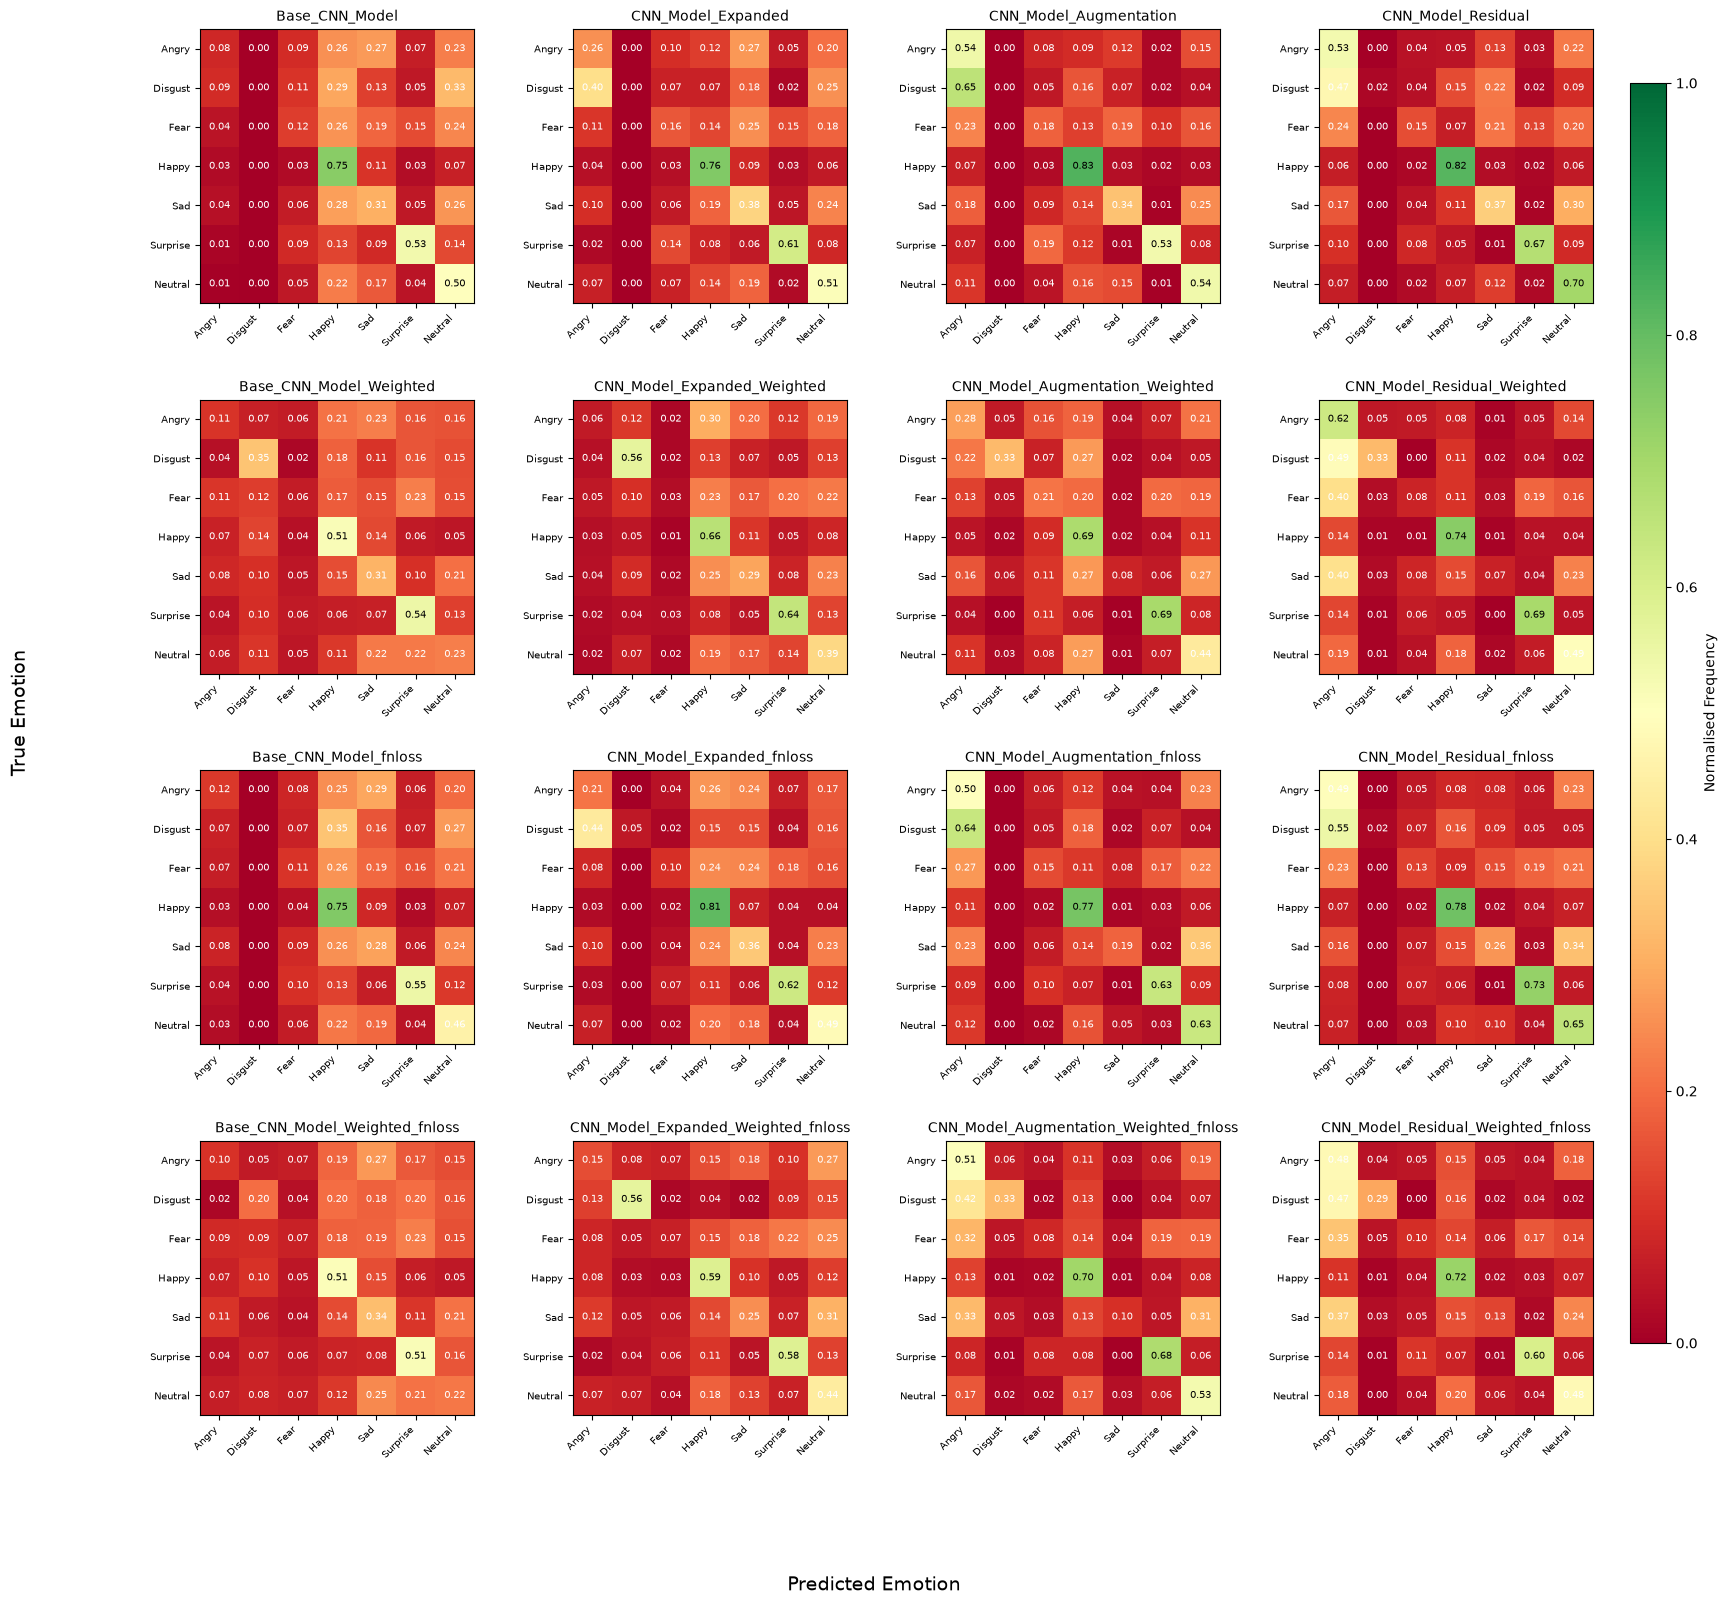

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(18, 18))

axes = axes.flatten()

model_names = list(CNN_MODELS.keys())

vmin = 0
vmax = 1

for ax, model_name in zip(axes, model_names):

    cm = pd.read_csv(
        f"confusion_matrices/{model_name}.csv"
    ).values

    im = ax.imshow(
        cm,
        cmap="RdYlGn",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(model_name, fontsize=10)

    ax.set_xticks(np.arange(len(EMOTION_LABELS)))

    ax.set_yticks(np.arange(len(EMOTION_LABELS)))

    ax.set_xticklabels(
        EMOTION_LABELS,
        rotation=45,
        ha="right",
        fontsize=7
    )

    ax.set_yticklabels(
        EMOTION_LABELS,
        fontsize=7
    )

    threshold = 0.50

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm[i, j]

            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center",
                color=(
                    "white"
                    if value < threshold
                    else "black"
                ),
                fontsize=7
            )

for ax in axes[len(model_names):]:
    ax.axis("off")

fig.supxlabel("Predicted Emotion", fontsize=14)

fig.supylabel("True Emotion", fontsize=14)

fig.subplots_adjust(
    right=0.90,
    wspace=0.35,
    hspace=0.35
)

cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])

fig.colorbar(
    im,
    cax=cbar_ax,
    label="Normalised Frequency"
)

plt.show()

The original implementation generated confusion matrices solely as evaluation outputs and displayed them individually. As the number of CNN architectures increased, comparing models one at a time became cumbersome and made it difficult to identify broader performance patterns.

The visualisation evolved into a multi-panel comparison figure capable of displaying every model simultaneously. Later, when the project was modularised and divided into separate execution stages, the plotting code was further revised to load confusion matrices from disk rather than from in-memory dictionaries.

## Evaluation:

This cell consolidates the large volume of evaluation results generated by the CNN experiments into a single, interpretable ranking table. During model development, each architecture produced multiple output files, including training histories, summary statistics, classification reports, confusion matrices, and saved model weights. While useful individually, these outputs made direct model comparison difficult.

The comparison table addresses this issue by extracting the most informative metrics from each model and presenting them in a standardised format. This allows all architectures to be evaluated simultaneously and provides a clear basis for selecting the strongest candidates for subsequent experimentation/conclusions.

The resulting table became particularly important because the project used repeated training runs rather than a single execution. Averaging results across multiple runs reduced the influence of random weight initialisation and provided a more reliable assessment of model performance.

One of the main challenges was determining how models should be ranked. Validation accuracy alone was found to be insufficient because it could favour models that performed well on dominant classes while performing poorly on minority emotions. To address this, balanced accuracy, macro F1-score, and macro recall were incorporated into the comparison process. These metrics provide a fairer evaluation of performance across all emotion classes and reduce the influence of class imbalance.

Another issue arose from comparing models with similar predictive performance but substantially different training requirements. Some architectures achieved only marginal improvements in accuracy while requiring significantly longer training times. To capture this trade-off, an Efficiency Score was introduced:
```python
CNN_comparison_df["Efficiency Score"] = (
    CNN_comparison_df["Mean Balanced Accuracy"] /
    CNN_comparison_df["Mean Training Time (s)"]
)
```
This metric provided additional insight into whether a performance improvement justified the additional computational cost.

The inclusion of Validation Accuracy Standard Deviation addressed a further concern regarding consistency. Some models produced strong average results but exhibited considerable variation between runs. Incorporating standard deviation into the ranking process helped identify models that were not only accurate but also reliable.

In [5]:
comparison_rows = []

for model_name in CNN_MODELS.keys():

    summary = pd.read_csv(
        f"results/{model_name}_summary.csv",
        index_col=0
    )

    report = pd.read_csv(
        f"reports/{model_name}_classification_report.csv",
        index_col=0
    )

    comparison_rows.append({
        "Model": model_name,
        "Mean Validation Accuracy":summary.loc["val_accuracy", "Mean"],
        "Mean Test Accuracy":summary.loc["test_accuracy", "Mean"],
        "Mean Balanced Accuracy":summary.loc["balanced_accuracy", "Mean"],
        "Mean Epochs":summary.loc["epochs", "Mean"],
        "Mean Training Time (s)":summary.loc["training_time_seconds", "Mean"],
        "Macro Precision":report.loc["macro avg", "precision"],
        "Macro Recall":report.loc["macro avg", "recall"],
        "Macro F1":report.loc["macro avg", "f1-score"],
        "Weighted F1":report.loc["weighted avg", "f1-score"],
        "Validation Accuracy Std": summary.loc["val_accuracy", "Std Dev"]
    })

CNN_comparison_df = pd.DataFrame(comparison_rows)

CNN_comparison_df["Efficiency Score"] = (
    CNN_comparison_df["Mean Balanced Accuracy"] /
    CNN_comparison_df["Mean Training Time (s)"]
)

CNN_comparison_df = CNN_comparison_df.sort_values(
    by=[
        "Mean Balanced Accuracy",
        "Macro F1",
        "Mean Validation Accuracy",
        "Mean Training Time (s)",
        "Validation Accuracy Std"
    ],
    ascending=[False, False, False, True, True]
)

CNN_comparison_df.to_csv("results/CNN_model_comparison.csv", index=False)

CNN_comparison_df

,Model,Mean Validation Accuracy,Mean Test Accuracy,Mean Balanced Accuracy,Mean Epochs,Mean Training Time (s),Macro Precision,Macro Recall,Macro F1,Weighted F1,Validation Accuracy Std,Efficiency Score
11,CNN_Model_Residual_fnloss,0.499749,0.505322,0.423988,59.6,159.456465,0.558304,0.438401,0.416389,0.492816,0.015539,0.002659
2,CNN_Model_Augmentation,0.485316,0.497743,0.412404,62.6,135.607251,0.423903,0.422672,0.415538,0.497562,0.019595,0.003041
3,CNN_Model_Residual,0.492616,0.496796,0.411158,58.6,159.176971,0.599894,0.464940,0.451246,0.535427,0.037654,0.002583
7,CNN_Model_Residual_Weighted,0.421956,0.421956,0.401442,56.0,150.944547,0.416073,0.432442,0.381964,0.423254,0.043769,0.002660
15,CNN_Model_Residual_Weighted_fnloss,0.413374,0.412873,0.390272,59.4,159.188842,0.386006,0.400486,0.370925,0.411951,0.017981,0.002452
10,CNN_Model_Augmentation_fnloss,0.464809,0.469156,0.388676,55.4,119.630062,0.411660,0.410157,0.387781,0.464553,0.016151,0.003249
14,CNN_Model_Augmentation_Weighted_fnloss,0.386960,0.383338,0.358256,61.8,135.498081,0.397815,0.418909,0.369595,0.413786,0.048328,0.002644
9,CNN_Model_Expanded_fnloss,0.434160,0.434160,0.349868,96.0,255.653065,0.432784,0.376768,0.364248,0.423703,0.028488,0.001369
6,CNN_Model_Augmentation_Weighted,0.383059,0.381722,0.349045,55.8,121.921698,0.366360,0.388087,0.348337,0.382491,0.027717,0.002863
1,CNN_Model_Expanded,0.434271,0.433268,0.346137,83.0,219.963085,0.373689,0.382171,0.372658,0.448753,0.032914,0.001574
